# Confiabilidade do detector binário de Aedes aegypti — 01/10/2026

**Ainda não confiável: falhou nos mínimos offline definidos antes do teste.** O modelo selecionado na validação foi **pcen_large**. No novo teste, sua precisão foi 10.3%, sensibilidade 2.7%, F1 de Aedes 4.2% e macro-F1 35.5%. Entre apenas mosquitos, a especificidade foi 75.7%. Não houve compilação, redução de modelo ou alteração de Arduino/instalador.

## O que conta como evidência de confiabilidade

Foi incorporado o [artigo indicado pelo usuário sobre os limites da acurácia](https://www.dio.me/articles/por-que-a-acuracia-accuracy-nao-e-a-melhor-metrica-para-avaliar-o-desempenho-de-classificadores). Se 99% da amostra for negativa, dizer sempre “não Aedes” dá 99% de acurácia e zero sensibilidade. Por isso, não usamos acurácia média acima de 60% como aprovação. As definições foram conferidas na [documentação oficial do Google](https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall).

- Precisão: dos alertas Aedes emitidos, quantos eram Aedes; depende da composição da amostra.
- Sensibilidade/recall: dos Aedes presentes, quantos foram detectados.
- Especificidade e falsos positivos: capacidade de rejeitar outros mosquitos e ruídos.
- F1 de Aedes e macro-F1: mostram o equilíbrio entre acertos/erros, incluindo as duas classes.
- Matriz de confusão, inválidos e cobertura: preservam os erros e as falhas de emissão no denominador.

O mínimo solicitado de 60% foi registrado no protocolo antes do teste: precisão, sensibilidade, macro-F1 e especificidade devem superar esse patamar tanto no conjunto completo quanto entre apenas mosquitos; cada táxon negativo deve ter especificidade de ao menos 60%. Exigimos também limites inferiores de 95% de ao menos 60% nas métricas principais por reamostragem de gravações. Esses mínimos são um filtro experimental, não uma certificação de uso.

O artigo contém uma inversão na explicação final do limiar: com scores fixos, aumentar o limiar nunca aumenta a sensibilidade. A precisão costuma aumentar, mas não é garantidamente monotônica; melhorar o modelo pode melhorar precisão e sensibilidade simultaneamente. [Explicação oficial do limiar](https://developers.google.com/machine-learning/crash-course/classification/thresholding).


## Treinamento ampliado e estratégias executadas

Foram adquiridas **670 gravações novas** para treino/validação/calibração, por regra de metadados registrada antes da inferência. Incluem HumBug e ESC-50; o conjunto ampliado tem **49.713 janelas** em todas as partições, não 49.713 observações biológicas independentes. Entraram também 30 negativos HumBug usados nos testes das rodadas anteriores: agora são adaptação, nunca teste inédito desta rodada.

Comparação pré-definida: quatro redes neurais e três modelos clássicos. Todas as redes têm cabeça de presença de mosquito e cabeça condicional de espécie, combinadas por P(mosquito) × P(Aedes | mosquito), com calibração Platt posterior. Esse produto é uma regra do detector, não prova de calibração probabilística perfeita. Os modelos clássicos usam os mesmos dois estágios, treinados separadamente.

- CNN residual expandida: 2.792.899 parâmetros.
- PCEN residual: 9.583.874 parâmetros; PCEN normaliza energia com uma média móvel causal, combinado com log-Mel relativo e contraste espectral.
- PCEN híbrida: 9.653.122 parâmetros, com 138 features acústicas adicionais, normalizadas somente no treino.
- CNN 1D em áudio bruto: 348.163 parâmetros, adaptada da arquitetura MosquitoSong+.
- ExtraTrees com profundidade 16, ExtraTrees sem limite de profundidade e HistGradientBoosting: alternativas em features acústicas.

Os lotes têm 48 Aedes, 48 outros mosquitos e 32 ruídos, com equilíbrio por fonte, táxon e gravação. O treino inclui ruído real em SNR 5–30 dB, equalização aleatória para simular diferenças de microfone e superposição de sons da mesma classe binária. Essas misturas são **simulações de treinamento**, não gravações independentes de enxames. Nenhum áudio privado, UFRGS ou CD-MSC D3 de Aedes entrou no treino.

Pré-processamento: mono, reamostragem real, retirada de componente DC e normalização de RMS. Entradas reais de 0,3 s ou 0,992 s; não repetimos, preenchemos ou concatenamos áudio para fabricar uma observação. A CNN 1D usa três recortes reais disjuntos quando recebe uma janela longa. O modelo híbrido combina features do trecho original com a onda aumentada durante treino; as features não são recalculadas após cada aumento.

Treino, validação, calibração e teste foram separados por gravação e hashes; as 212 janelas de mosquito sem espécie continuam não rotuladas. Complexos cujo gênero é comprovadamente não Aedes podem ser negativos binários, mas não equivalem a identificação exata de espécie. A categoria ESC-50 “insects” foi excluída por ambiguidade de presença de mosquito.


In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
ROOT = Path.cwd()
if not (ROOT / 'results/reliability_2026_10_01').exists(): ROOT = ROOT.parent
O = ROOT / 'results/reliability_2026_10_01'
decision = json.loads((O / 'reliability_decision.json').read_text())
selected = decision['selected_model']
metrics = pd.read_csv(O / 'fresh_metrics.csv')
display(decision)

{'completed_utc': '2026-10-01T22:22:42.123595+00:00',
 'selected_model': 'pcen_large',
 'offline_minimum_criteria_passed': False,
 'failure_reasons': ['all_fresh: aedes_precision below .60',
  'all_fresh: aedes_precision lower95 below .60',
  'all_fresh: aedes_recall below .60',
  'all_fresh: aedes_recall lower95 below .60',
  'all_fresh: macro_f1 below .60',
  'all_fresh: macro_f1 lower95 below .60',
  'mosquito_only: aedes_precision below .60',
  'mosquito_only: aedes_precision lower95 below .60',
  'mosquito_only: aedes_recall below .60',
  'mosquito_only: aedes_recall lower95 below .60',
  'mosquito_only: macro_f1 below .60',
  'mosquito_only: macro_f1 lower95 below .60',
  'CDMSC2026_D3: aedes_precision below .60',
  'CDMSC2026_D3: aedes_precision lower95 below .60',
  'CDMSC2026_D3: aedes_recall below .60',
  'CDMSC2026_D3: aedes_recall lower95 below .60',
  'CDMSC2026_D3: macro_f1 below .60',
  'CDMSC2026_D3: macro_f1 lower95 below .60',
  'taxon:Aedes aegypti: aedes_recall belo

## Treinamento, seleção anterior ao teste e auditoria

In [2]:
display(pd.read_json(O / 'validation_search.json')[['name','validation_minimum_recall','validation_precision','validation_recall','validation_macro_f1','cut']])
display(json.loads((O / 'freeze.json').read_text()))
display(pd.read_csv(O / 'fresh_novelty_audit.csv'))

,name,validation_minimum_recall,validation_precision,validation_recall,validation_macro_f1,cut
0,residual_expanded,0.364095,0.151096,0.543568,0.584013,0.348828
1,pcen_large,0.426691,0.158127,0.742739,0.588419,0.506409
2,pcen_hybrid_large,0.331478,0.131299,0.767635,0.557976,0.426877
3,raw_expanded,0.333333,0.068356,0.369295,0.500457,0.551765
4,trees_regularized,0.140125,0.073634,0.257261,0.518538,0.341920
5,trees_deep,0.100710,0.070539,0.211618,0.518441,0.407534
6,hist_gradient_boosting,0.302302,0.119171,0.477178,0.555565,0.387954


{'frozen_utc': '2026-10-01T22:16:05.106583+00:00',
 'models_sha256': {'results/reliability_2026_10_01/models/residual_expanded.pt': 'e60490372de0e42a8b7b35fd676707886b1cca763d86531c35c63c7022c17385',
  'results/reliability_2026_10_01/models/pcen_large.pt': 'aab45f856d90c0f8921c09fa45c185870b33b8939e149495d277c2706d7b39ee',
  'results/reliability_2026_10_01/models/pcen_hybrid_large.pt': 'f77fef396f19f96d8cd0fe709bd26615bd998e44bd7be390d9109d343ca85c5b',
  'results/reliability_2026_10_01/models/raw_expanded.pt': 'c9d1b50da1727c75fab1aa7ed249e8a19cb6f0bc609941f9eebda5d635eb7500',
  'results/reliability_2026_10_01/models/trees_regularized.joblib': 'e7163c8eca21c26f527ef3ba8af1337e55bdc474f3d6161403fcbac0e2419f65',
  'results/reliability_2026_10_01/models/trees_deep.joblib': '6c5d1e8837c741ae890bcde28c98e0efdd64b27b3c96d0212fd862df4e4c3d2e',
  'results/reliability_2026_10_01/models/hist_gradient_boosting.joblib': 'bdadbe08501b0275d54cbafa799df44a5331607ac16d63bcf3e14b5f6d029986'},
 'source_

,path,windows,exact_pcm_windows_seen,duplicate_file,original_recording_identity_available
0,data/external/reliability_fresh_2026_10_01/S_1...,35,0,False,False
1,data/external/reliability_fresh_2026_10_01/S_1...,33,0,False,False
2,data/external/reliability_fresh_2026_10_01/S_1...,34,0,False,False
3,data/external/reliability_fresh_2026_10_01/S_1...,29,0,False,False
4,data/external/reliability_fresh_2026_10_01/S_1...,36,0,False,False
...,...,...,...,...,...
177,data/external/reliability_fresh_2026_10_01/5-1...,5,0,False,True
178,data/external/reliability_fresh_2026_10_01/5-2...,5,0,False,True
179,data/external/reliability_fresh_2026_10_01/5-2...,5,0,False,True
180,data/external/reliability_fresh_2026_10_01/5-1...,5,0,False,True


## Precisão, sensibilidade e F1 — comparação dos modelos congelados

In [3]:
cols = ['model','selected','known_windows','aedes_precision','aedes_recall','aedes_f1','macro_f1','specificity','accuracy']
display(metrics[metrics.scope.eq('all_fresh')][cols])
display(metrics[metrics.scope.eq('mosquito_only')][cols])

,model,selected,known_windows,aedes_precision,aedes_recall,aedes_f1,macro_f1,specificity,accuracy
0,hist_gradient_boosting,False,1933,0.379085,0.147583,0.212454,0.449559,0.828248,0.551474
25,pcen_hybrid_large,False,1933,0.351682,0.146310,0.206649,0.441270,0.809067,0.539576
50,pcen_large,True,1933,0.102941,0.026718,0.042424,0.354778,0.834350,0.505949
75,previous_round3_extra_trees_regularized,False,1933,0.450942,0.578880,0.506964,0.537397,0.510898,0.538541
100,raw_expanded,False,1933,0.187302,0.075064,0.107175,0.374110,0.770706,0.487843
125,residual_expanded,False,1933,0.480342,0.357506,0.409920,0.540973,0.728858,0.577858
150,trees_deep,False,1933,0.556575,0.463104,0.505556,0.604163,0.741064,0.628039
175,trees_regularized,False,1933,0.564692,0.594148,0.579045,0.636807,0.680035,0.645111


,model,selected,known_windows,aedes_precision,aedes_recall,aedes_f1,macro_f1,specificity,accuracy
1,hist_gradient_boosting,False,1445,0.409894,0.147583,0.217025,0.378694,0.746586,0.420761
26,pcen_hybrid_large,False,1445,0.353846,0.146310,0.207021,0.355899,0.681335,0.390311
51,pcen_large,True,1445,0.116022,0.026718,0.043433,0.281207,0.757208,0.359862
76,previous_round3_extra_trees_regularized,False,1445,0.526620,0.578880,0.551515,0.477370,0.379363,0.487889
101,raw_expanded,False,1445,0.200680,0.075064,0.109259,0.288884,0.643399,0.334256
126,residual_expanded,False,1445,0.548828,0.357506,0.432974,0.485331,0.649469,0.490657
151,trees_deep,False,1445,0.634146,0.463104,0.535294,0.561111,0.681335,0.562630
176,trees_regularized,False,1445,0.626846,0.594148,0.610059,0.585383,0.578149,0.586851


## Curvas precisão–sensibilidade

Diagnóstico dos scores brutos, sem escolher novo limiar; inválidos permanecem explícitos na matriz operacional. Linhas horizontais mostram a prevalência de Aedes de cada amostra.

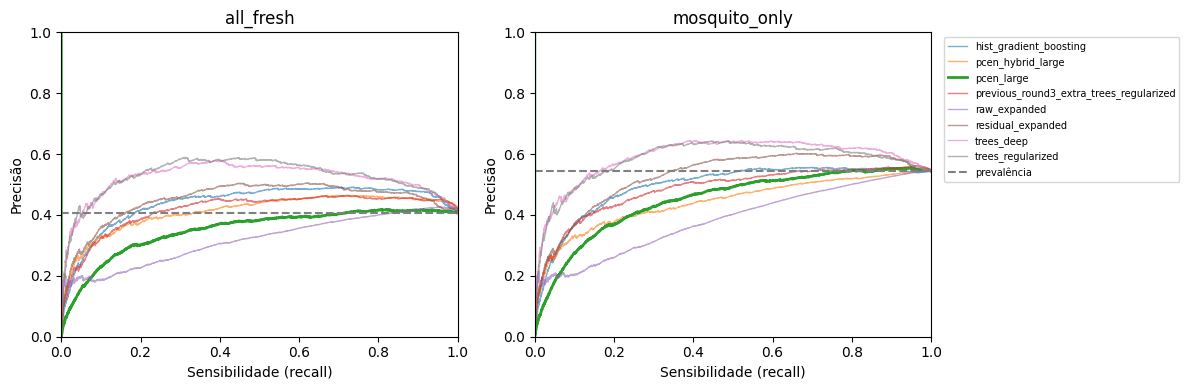

In [4]:
pred = pd.read_csv(O / 'fresh_predictions.csv.gz')
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, scope in zip(axes,['all_fresh','mosquito_only']):
    sample = pred if scope == 'all_fresh' else pred[pred.reference_species.ne('noise')]
    for name, s in sample.groupby('model'):
        precision, recall, _ = precision_recall_curve(s.label,s.score)
        ax.plot(recall,precision,label=name,linewidth=2 if name == selected else 1,alpha=1 if name == selected else .6)
    ax.axhline(sample[sample.model.eq(selected)].label.mean(),color='gray',linestyle='--',label='prevalência')
    ax.set(xlabel='Sensibilidade (recall)',ylabel='Precisão',title=scope,xlim=(0,1),ylim=(0,1))
axes[1].legend(fontsize=7,bbox_to_anchor=(1.02,1))
fig.tight_layout()
assets=ROOT/'reports/assets'; assets.mkdir(exist_ok=True)
fig.savefig(assets/'aedes_reliability_precision_recall.png',dpi=200,bbox_inches='tight')
plt.show()

## Matriz com inválidos e acerto por táxon

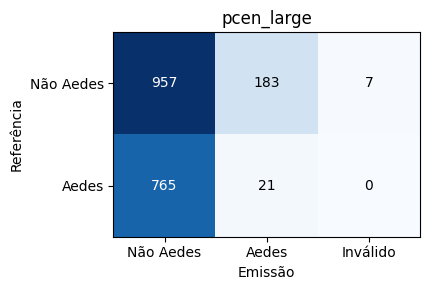

,scope,groups,known_windows,true_positive,false_positive,false_negative,true_negative,invalid,aedes_recall,specificity
56,taxon:Aedes aegypti,24,786,21,0,765,0,0,0.026718,NaN
57,taxon:Aedes albopictus,6,180,0,4,0,176,0,NaN,0.977778
58,taxon:Anopheles arabiensis,3,6,0,0,0,6,0,NaN,1.000000
59,taxon:Anopheles barbirostris,1,11,0,0,0,11,0,NaN,1.000000
60,taxon:Anopheles coustani,3,11,0,8,0,3,0,NaN,0.272727
61,taxon:Anopheles dirus,1,2,0,0,0,2,0,NaN,1.000000
62,taxon:Anopheles funestus sl,3,22,0,21,0,1,0,NaN,0.045455
63,taxon:Anopheles funestus ss,3,81,0,78,0,3,0,NaN,0.037037
64,taxon:Anopheles harrisoni,3,28,0,0,0,28,0,NaN,1.000000
65,taxon:Anopheles maculatus,3,18,0,0,0,18,0,NaN,1.000000


In [5]:
r=metrics[metrics.model.eq(selected)&metrics.scope.eq('all_fresh')].iloc[0]
matrix=np.array(json.loads(r.confusion))
fig, ax=plt.subplots(figsize=(6,3)); ax.imshow(matrix,cmap='Blues')
for (i,j),v in np.ndenumerate(matrix): ax.text(j,i,str(v),ha='center',va='center',color='white' if v>matrix.max()/2 else 'black')
ax.set_xticks([0,1,2],['Não Aedes','Aedes','Inválido']); ax.set_yticks([0,1],['Não Aedes','Aedes'])
ax.set(xlabel='Emissão',ylabel='Referência',title=selected); fig.tight_layout()
fig.savefig(assets/'aedes_reliability_confusion.png',dpi=200)
plt.show()
display(metrics[metrics.model.eq(selected)&metrics.scope.str.startswith('taxon:')][['scope','groups','known_windows','true_positive','false_positive','false_negative','true_negative','invalid','aedes_recall','specificity']])

## Intervalos por gravação e áudio privado

Aedes no Drive é uma referência conhecida, não um teste cego; não mede especificidade ou precisão binária. CD-MSC tem identidade individual incompleta.

In [6]:
display(json.loads((O / 'fresh_group_bootstrap.json').read_text())[selected])
display(pd.read_csv(O / 'private_audio_aggregate_exploratory.csv')[['model','selected','known_windows','true_positive','aedes_recall','invalid','precision_informative_for_binary_detection']])
display(pd.read_csv(O / 'historical_metrics_exploratory.csv'))

{'all_fresh': {'method': '2000 bootstrap replicates, original recording groups stratified by source; CDMSC file identity only, not independent individuals.',
  'groups': 166,
  'metrics': {'aedes_precision': {'lower95': 0.016212417236513624,
    'upper95': 0.2580698568681905},
   'aedes_recall': {'lower95': 0.004464285714285714,
    'upper95': 0.06186410125571263},
   'aedes_f1': {'lower95': 0.007034983486170821,
    'upper95': 0.09633956650795053},
   'specificity': {'lower95': 0.7472420274824993, 'upper95': 0.90656595747754},
   'macro_f1': {'lower95': 0.3074666565022564, 'upper95': 0.4048368446063174},
   'balanced_accuracy': {'lower95': 0.38424680214616613,
    'upper95': 0.47102630469626533}}},
 'mosquito_only': {'method': '2000 bootstrap replicates, original recording groups stratified by source; CDMSC file identity only, not independent individuals.',
  'groups': 82,
  'metrics': {'aedes_precision': {'lower95': 0.019479887816463693,
    'upper95': 0.29667994519435664},
   'aedes

,model,selected,known_windows,true_positive,aedes_recall,invalid,precision_informative_for_binary_detection
0,residual_expanded,False,107,37,0.345794,2,False
1,pcen_large,True,107,39,0.364486,2,False
2,pcen_hybrid_large,False,107,11,0.102804,2,False
3,raw_expanded,False,107,17,0.158879,2,False
4,trees_regularized,False,107,74,0.691589,2,False
5,trees_deep,False,107,81,0.757009,2,False
6,hist_gradient_boosting,False,107,53,0.495327,2,False
7,previous_round3_extra_trees_regularized,False,107,77,0.719626,2,False


,model,selected,scope,groups,known_windows,unknown_windows,invalid,confusion_rows,confusion_columns,confusion,...,non_aedes_f1,macro_f1,balanced_accuracy,emitted_false_positive_rate,coverage,accuracy,roc_auc,average_precision,mcc_on_valid_audio,threshold
0,residual_expanded,False,dryad,204,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6724, 817, 0], [2, 358, 0]]",...,0.942595,0.704522,0.943052,0.108341,1.000000,0.896342,0.990985,0.865605,0.519341,0.348828
1,residual_expanded,False,humbug,41,1298,212,2,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[797, 345, 2], [10, 144, 0]]",...,0.817017,0.632459,0.815872,0.301573,0.998459,0.724961,0.948041,0.857164,0.422553,0.348828
2,residual_expanded,False,mosquitosong,2,352,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[0, 0, 0], [134, 218, 0]]",...,NaN,NaN,NaN,NaN,1.000000,0.619318,NaN,NaN,NaN,0.348828
3,residual_expanded,False,ufrgs,3,417,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[110, 36, 0], [39, 232, 0]]",...,0.745763,0.803308,0.804757,0.246575,1.000000,0.820144,0.893697,0.946241,0.606714,0.348828
4,pcen_large,True,dryad,204,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[7182, 359, 0], [30, 330, 0]]",...,0.973632,0.801402,0.934530,0.047606,1.000000,0.950766,0.983784,0.800114,0.642359,0.506409
5,pcen_large,True,humbug,41,1298,212,2,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[853, 289, 2], [3, 151, 0]]",...,0.853000,0.680709,0.863074,0.252622,0.998459,0.773498,0.969139,0.867580,0.497091,0.506409
6,pcen_large,True,mosquitosong,2,352,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[0, 0, 0], [240, 112, 0]]",...,NaN,NaN,NaN,NaN,1.000000,0.318182,NaN,NaN,NaN,0.506409
7,pcen_large,True,ufrgs,3,417,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[145, 1, 0], [172, 99, 0]]",...,0.626350,0.580021,0.679232,0.006849,1.000000,0.585132,0.929662,0.960026,0.400477,0.506409
8,pcen_hybrid_large,False,dryad,204,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6706, 835, 0], [22, 338, 0]]",...,0.939940,0.690453,0.914080,0.110728,1.000000,0.891533,0.966094,0.511472,0.485723,0.426877
9,pcen_hybrid_large,False,humbug,41,1298,212,2,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[1078, 64, 2], [13, 141, 0]]",...,0.964653,0.875084,0.928946,0.055944,0.998459,0.939137,0.978368,0.906250,0.762204,0.426877


## Explicação dos estágios e importância das árvores

Scores de presença/espécie são diagnósticos. Importância por impureza não é uma explicação causal e não descreve a rede neural.

In [7]:
stages = pd.read_csv(O / 'stage_explanations.csv')
display(stages[stages.model.eq(selected)])
importance = pd.read_csv(O / 'classical_feature_importance_exploratory.csv')
display(importance.sort_values('impurity_importance',ascending=False).groupby(['model','stage']).head(10))

,model,reference_species,presence_stage_score,conditional_species_score,score
38,pcen_large,Aedes aegypti,0.974731,0.005219,0.067031
39,pcen_large,Aedes albopictus,0.985192,0.006342,0.076817
40,pcen_large,Anopheles arabiensis,0.968022,0.002846,0.066890
41,pcen_large,Anopheles barbirostris,0.994604,0.000588,0.025456
42,pcen_large,Anopheles coustani,0.998177,0.330300,0.663227
43,pcen_large,Anopheles dirus,0.673510,0.002897,0.041335
44,pcen_large,Anopheles funestus sl,0.999476,0.818244,0.889600
45,pcen_large,Anopheles funestus ss,0.999379,0.912670,0.931654
46,pcen_large,Anopheles harrisoni,0.996628,0.000654,0.027264
47,pcen_large,Anopheles maculatus,0.994941,0.000906,0.033384


,model,stage,feature,impurity_importance
56,trees_regularized,presence_model,low_peak_hz_mean,0.084805
332,trees_deep,presence_model,low_peak_hz_mean,0.080392
95,trees_regularized,presence_model,cepstrum_4_std,0.047729
36,trees_regularized,presence_model,cepstrum_6_mean,0.045540
371,trees_deep,presence_model,cepstrum_4_std,0.043898
312,trees_deep,presence_model,cepstrum_6_mean,0.041112
94,trees_regularized,presence_model,cepstrum_3_std,0.040600
370,trees_deep,presence_model,cepstrum_3_std,0.038219
92,trees_regularized,presence_model,cepstrum_1_std,0.037556
368,trees_deep,presence_model,cepstrum_1_std,0.036043


| Candidato | Época selecionada | Menor recall de validação por fonte/classe | Precisão na validação | Limiar da calibração |
| --- | --- | --- | --- | --- |
| residual_expanded | 11 | 36.4% | 15.1% | 0.3488 |
| pcen_large | 13 | 42.7% | 15.8% | 0.5064 |
| pcen_hybrid_large | 1 | 33.1% | 13.1% | 0.4269 |
| raw_expanded | 10 | 33.3% | 6.8% | 0.5518 |
| trees_regularized | árvores | 14.0% | 7.4% | 0.3419 |
| trees_deep | árvores | 10.1% | 7.1% | 0.4075 |
| hist_gradient_boosting | árvores | 30.2% | 11.9% | 0.3880 |

Seleção: maior mínimo de recall por fonte/classe na validação, com pequenos termos de macro-F1 e average precision. Limiar: somente calibração, sem rótulos do teste. Congelamento: **2026-10-01T22:16:05.106583+00:00**. Seleção dos novos áudios: **2026-10-01T22:16:32.502892+00:00**. Todos os pesos e fontes congelados têm SHA-256; os 12 checkpoints anteriores permaneceram idênticos.

## Novo teste baixado depois do congelamento

Foram baixados **182 arquivos**, dos quais 166 foram avaliados após auditoria de duplicatas. A regra de seleção foi: First 24 unused acoustic class-1/domain-3 WAVs in full archive numeric order, plus first6/domain3 each of classes2,7,8,9 as SAME-domain negatives; first 3 unused HumBug recording groups per known non-Aedes taxon and noise; ESC50 fold5 first2 distinct original sources/category excluding flying insects.

Positivos: arquivos acústicos CD-MSC 2026, domínio D3, com rótulo Aedes aegypti. Negativos: novos grupos HumBug, fontes ESC-50 do fold 5 e **CD-MSC D3 com Aedes albopictus, Culex pipiens, Anopheles minimus e Anopheles stephensi**. Esse subconjunto inclui as duas classes no mesmo domínio acústico. O domínio D5 óptico foi excluído. [Dataset oficial CD-MSC 2026](https://zenodo.org/records/19095788), [HumBugDB](https://zenodo.org/records/4904800), [ESC-50 e agrupamento das fontes](https://github.com/karolpiczak/ESC-50).

**Limites:** D3 não fornece neste recorte identidade do mosquito ou sessão original; são arquivos novos, não indivíduos ou campanhas comprovadamente novos. HumBug só acrescenta negativos frescos, o que mantém confusão entre classe e fonte no agregado; reportamos também o D3 com as duas classes. O rótulo é do arquivo e não uma anotação de presença de batimento em cada instante. Isso impede extrapolar o teste a qualquer microfone, caixa ou enxame. O bootstrap por arquivo não corrige essa ausência de metadados.


| Fonte | Arquivos | Segundos |
| --- | --- | --- |
| CDMSC2026_D3 | 48 | 1008.4 |
| ESC50_noise | 97 | 485.0 |
| HumBug_noise | 3 | 83.8 |
| HumBug_other_mosquito | 34 | 455.4 |

A auditoria excluiu conservadoramente 16 arquivos ESC-50 que continham alguma janela PCM quantizada igual a uma janela anterior. O esclarecimento posterior mostrou que as 37 correspondências eram janelas constantes/silenciosas, não cópias demonstradas das gravações inteiras. A coluna `duplicate_file` sinaliza esse critério de colisão de janela. Mantivemos a exclusão pré-definida e não escolhemos substitutos; os resultados não foram recalculados para favorecer o modelo. Ver `novelty_clarification.json`.

## Comparação de todos os candidatos congelados

O vencedor foi escolhido antes do teste. Um candidato com melhor resultado neste teste não é automaticamente promovido: isso usaria o teste para seleção.

A linha `previous_round3_extra_trees_regularized` é o modelo previamente selecionado na rodada 3, preservado e avaliado nos mesmos áudios novos para comparação; não participou da seleção nesta rodada.

| Modelo | Selecionado antes do teste | Precisão | Recall Aedes | F1 Aedes | Macro-F1 | Especificidade | Acurácia |
| --- | --- | --- | --- | --- | --- | --- | --- |
| hist_gradient_boosting | não | 37.9% | 14.8% | 21.2% | 45.0% | 82.8% | 55.1% |
| pcen_hybrid_large | não | 35.2% | 14.6% | 20.7% | 44.1% | 80.9% | 54.0% |
| pcen_large | sim | 10.3% | 2.7% | 4.2% | 35.5% | 83.4% | 50.6% |
| previous_round3_extra_trees_regularized | não | 45.1% | 57.9% | 50.7% | 53.7% | 51.1% | 53.9% |
| raw_expanded | não | 18.7% | 7.5% | 10.7% | 37.4% | 77.1% | 48.8% |
| residual_expanded | não | 48.0% | 35.8% | 41.0% | 54.1% | 72.9% | 57.8% |
| trees_deep | não | 55.7% | 46.3% | 50.6% | 60.4% | 74.1% | 62.8% |
| trees_regularized | não | 56.5% | 59.4% | 57.9% | 63.7% | 68.0% | 64.5% |

## Melhorou em relação ao modelo anterior?

Diferenças na mesma amostra, em pontos percentuais: nova rede escolhida na validação menos ExtraTrees escolhido na rodada 3. Intervalos pareados por arquivo/gravação, exploratórios; ganho parcial não implica aprovação de confiabilidade.

| Condição | Métrica | Mudança | IC 95% da mudança |
| --- | --- | --- | --- |
| all_fresh | aedes_precision | -34.8 pp | -47.6 a -20.2 pp |
| all_fresh | aedes_recall | -55.2 pp | -62.9 a -47.2 pp |
| all_fresh | aedes_f1 | -46.5 pp | -54.9 a -36.8 pp |
| all_fresh | specificity | +32.3 pp | +23.5 a +40.7 pp |
| all_fresh | macro_f1 | -18.3 pp | -25.9 a -9.9 pp |
| all_fresh | balanced_accuracy | -11.4 pp | -17.3 a -5.8 pp |
| mosquito_only | aedes_precision | -41.1 pp | -56.0 a -25.0 pp |
| mosquito_only | aedes_recall | -55.2 pp | -62.9 a -47.2 pp |
| mosquito_only | aedes_f1 | -50.8 pp | -59.6 a -40.7 pp |
| mosquito_only | specificity | +37.8 pp | +23.5 a +50.2 pp |
| mosquito_only | macro_f1 | -19.6 pp | -29.0 a -9.7 pp |
| mosquito_only | balanced_accuracy | -8.7 pp | -16.9 a -1.2 pp |
| CDMSC2026_D3 | aedes_precision | -25.4 pp | -64.0 a -0.9 pp |
| CDMSC2026_D3 | aedes_recall | -55.2 pp | -62.9 a -47.2 pp |
| CDMSC2026_D3 | aedes_f1 | -61.8 pp | -69.8 a -52.7 pp |
| CDMSC2026_D3 | specificity | +46.8 pp | +27.0 a +66.5 pp |
| CDMSC2026_D3 | macro_f1 | -29.2 pp | -37.1 a -19.3 pp |
| CDMSC2026_D3 | balanced_accuracy | -4.2 pp | -15.3 a +6.5 pp |

## Resultado do modelo selecionado por condição

| Condição | Janelas | Precisão | Recall Aedes | Especificidade | Falsos positivos | Macro-F1 |
| --- | --- | --- | --- | --- | --- | --- |
| all_fresh | 1933 | 10.3% | 2.7% | 83.4% | 16.0% | 35.5% |
| mosquito_only | 1445 | 11.6% | 2.7% | 75.7% | 24.3% | 28.1% |
| CDMSC2026_D3 | 1002 | 53.8% | 2.7% | 91.7% | 8.3% | 19.3% |
| ESC50_noise | 405 | não estimável como detector binário | — | 92.6% | 5.7% | — |
| HumBug_noise | 83 | não estimável como detector binário | — | 100.0% | 0.0% | — |
| HumBug_other_mosquito | 443 | não estimável como detector binário | — | 67.9% | 32.1% | — |

## Acertos e erros por táxon

O detector emite somente Aedes/não Aedes; as linhas abaixo medem rejeição de cada táxon conhecido, não classificação multiclasse. Complexos mantêm sua identificação taxonômica incompleta.

| Referência | Grupos | Janelas | Aedes emitido | Não Aedes emitido | Inválidos | Taxa de acerto relevante |
| --- | --- | --- | --- | --- | --- | --- |
| Aedes aegypti | 24 | 786 | 21 | 765 | 0 | 2.7% |
| Aedes albopictus | 6 | 180 | 4 | 176 | 0 | 97.8% |
| Anopheles arabiensis | 3 | 6 | 0 | 6 | 0 | 100.0% |
| Anopheles barbirostris | 1 | 11 | 0 | 11 | 0 | 100.0% |
| Anopheles coustani | 3 | 11 | 8 | 3 | 0 | 27.3% |
| Anopheles dirus | 1 | 2 | 0 | 2 | 0 | 100.0% |
| Anopheles funestus sl | 3 | 22 | 21 | 1 | 0 | 4.5% |
| Anopheles funestus ss | 3 | 81 | 78 | 3 | 0 | 3.7% |
| Anopheles harrisoni | 3 | 28 | 0 | 28 | 0 | 100.0% |
| Anopheles maculatus | 3 | 18 | 0 | 18 | 0 | 100.0% |
| Anopheles maculipalpis | 3 | 110 | 4 | 106 | 0 | 96.4% |
| Anopheles minimus | 6 | 12 | 3 | 9 | 0 | 75.0% |
| Anopheles squamosus | 3 | 19 | 0 | 19 | 0 | 100.0% |
| Anopheles stephensi | 6 | 12 | 1 | 11 | 0 | 91.7% |
| Culex pipiens | 6 | 12 | 10 | 2 | 0 | 16.7% |
| Culex pipiens complex | 3 | 114 | 27 | 87 | 0 | 76.3% |
| Mansonia africanus | 2 | 7 | 2 | 5 | 0 | 71.4% |
| Mansonia uniformis | 3 | 14 | 2 | 12 | 0 | 85.7% |
| noise | 84 | 488 | 23 | 458 | 7 | 93.9% |

## Matriz de confusão do novo teste

Linhas são a referência; colunas são emissões. Inválidos não contam como rejeições corretas.

| Referência | Não Aedes | Aedes | Inválido |
| --- | --- | --- | --- |
| Não Aedes | 957 | 183 | 7 |
| Aedes | 765 | 21 | 0 |

## Intervalos de incerteza

Reamostragem estratificada por fonte com 2.000 repetições de grupos/arquivos inteiros. Mantém a correlação entre janelas; não comprova independência biológica dos arquivos CD-MSC.

| Condição | Métrica | IC 95% por gravação/arquivo |
| --- | --- | --- |
| all_fresh | aedes_precision | 1.6%–25.8% |
| all_fresh | aedes_recall | 0.4%–6.2% |
| all_fresh | aedes_f1 | 0.7%–9.6% |
| all_fresh | specificity | 74.7%–90.7% |
| all_fresh | macro_f1 | 30.7%–40.5% |
| all_fresh | balanced_accuracy | 38.4%–47.1% |
| mosquito_only | aedes_precision | 1.9%–29.7% |
| mosquito_only | aedes_recall | 0.4%–6.2% |
| mosquito_only | aedes_f1 | 0.7%–9.9% |
| mosquito_only | specificity | 60.3%–87.3% |
| mosquito_only | macro_f1 | 20.8%–34.9% |
| mosquito_only | balanced_accuracy | 31.4%–45.4% |
| CDMSC2026_D3 | aedes_precision | 14.3%–79.2% |
| CDMSC2026_D3 | aedes_recall | 0.4%–6.2% |
| CDMSC2026_D3 | aedes_f1 | 0.9%–11.4% |
| CDMSC2026_D3 | specificity | 81.1%–96.0% |
| CDMSC2026_D3 | macro_f1 | 9.4%–28.9% |
| CDMSC2026_D3 | balanced_accuracy | 41.9%–50.1% |

## Áudio privado do Drive

Referência fornecida pelo usuário: enxame de Aedes em caixa de vidro gravado pelo Nano 33 BLE Sense, com mosquito em todo o áudio. Todos os 107 trechos permanecem no denominador; dois são inválidos. É uma gravação conhecida e não um teste cego. Não foi usada no treino e não será publicada. Como só há positivos, o acerto mede sensibilidade nessa gravação; a precisão aparente de 100% não informa falsos alarmes.

| Modelo | Selecionado | Aedes detectados | Sensibilidade nesse áudio | Inválidos |
| --- | --- | --- | --- | --- |
| residual_expanded | não | 37/107 | 34.6% | 2 |
| pcen_large | sim | 39/107 | 36.4% | 2 |
| pcen_hybrid_large | não | 11/107 | 10.3% | 2 |
| raw_expanded | não | 17/107 | 15.9% | 2 |
| trees_regularized | não | 74/107 | 69.2% | 2 |
| trees_deep | não | 81/107 | 75.7% | 2 |
| hist_gradient_boosting | não | 53/107 | 49.5% | 2 |
| previous_round3_extra_trees_regularized | não | 77/107 | 72.0% | 2 |

## Bases históricas: diagnóstico de regressões

Já examinadas no desenvolvimento; não são um novo teste independente. UFRGS permanece ausente do treino. MosquitoSong challenge só tem Aedes: não fornece precisão/especificidade binárias.

| Fonte | Janelas | Precisão | Recall Aedes | Especificidade | Macro-F1 |
| --- | --- | --- | --- | --- | --- |
| dryad | 7901 | 47.9% | 91.7% | 95.2% | 80.1% |
| humbug | 1298 | 34.3% | 98.1% | 74.6% | 68.1% |
| mosquitosong | 352 | somente positivos | 31.8% | — | — |
| ufrgs | 417 | 99.0% | 36.5% | 99.3% | 58.0% |

## Reprodução dos estudos e rodadas anteriores

As comparações anteriores desta sessão ficam em `results/reproduction_2026_10_01/`. Foram executadas adaptações da CNN Mel de Fernandes, CNN 1D de MosquitoSong+, CNN residual e alinhamento de embeddings entre fontes da mesma espécie, além de árvores. São reproduções de estratégias, **não equivalência exata aos experimentos publicados**: tarefa, recortes, agrupamento e fontes de teste diferem.

- Fernandes: convoluções 32/64/64 e Dense 256, 1.137.601 parâmetros, Mel 60×40; BCE binária em vez dos dois sigmoides originais e interpolação do espectrograma para durações reais.
- MosquitoSong+: arquitetura 1D da figura 2, áudio de 0,3 s; adaptação de quatro classes para uma saída binária.
- Residual: 2.791.873 parâmetros; ruído e misturas de mesma classe no treino. Alinhamento contrastivo inspirado em trabalhos de adaptação de domínio; não reproduz integralmente o DR-BioL.

Rodada 1: rede residual com ruído escolhida na validação. Novo teste de 19 negativos: 334/544 falsos Aedes (61,4%); nos outros mosquitos, 67/103 (65,0%). Não houve positivo acústico novo nessa rodada. Áudio privado: 20/107 detectados.

Rodada 2: busca de 105 ensembles, selecionada só na validação; melhor mínimo de recall por fonte/classe ainda 38,8%. Áudio privado: 55/107. Os negativos da rodada 1 são diagnósticos reutilizados nesta etapa.

Rodada 3: 19 negativos anteriores incorporados ao treino. ExtraTrees regularizado foi escolhido antes do novo teste de 23 arquivos, contendo 12 positivos CD-MSC novos. Detectou 216/358 Aedes (60,3%), mas confundiu 33/47 outros mosquitos (70,2%). Precisão 64,9%, F1 Aedes 62,5%, acurácia balanceada operacional 64,8%. O resultado médio passou de 60% e **continuou inadequado entre espécies**. Outro candidato de árvores foi melhor nesse teste, mas não pode substituir retrospectivamente o vencedor sem uma nova validação. Áudio privado: 77/107.

Os 12 positivos foram escolhidos no prefixo de 8 MiB do diretório central ZIP64, não na lista completa do arquivo; a limitação está registrada no adendo da seleção. A rodada ampliada usa a lista completa de 542.777 entradas, com 192 arquivos D3 de Aedes. Os 12 anteriores estão excluídos do novo teste e de todo treino.

Os resultados publicados nos estudos não comprovam confiabilidade no nosso domínio: não fizemos uma comparação na mesma amostra, rótulos e protocolo. Por isso, não afirmamos superar Fernandes ou MosquitoSong+. A pesquisa bibliográfica está em [estudos_detector_binario_aedes_2026_10_01.md](reports/estudos_detector_binario_aedes_2026_10_01.md).


## Explicabilidade e limites

Registramos os scores dos dois estágios, presença e espécie condicional, em cada janela pública, para localizar a etapa da falha. A tabela abaixo traz medianas por táxon; não são taxas de acerto nem probabilidades comprovadamente calibradas em campo. Na CNN 1D longa, cada estágio é uma média de três recortes e o score conjunto é a média dos produtos por recorte, não o produto das médias.

| Referência | Score presença, mediana | Score Aedes condicional, mediana | Score final calibrado, mediana |
| --- | --- | --- | --- |
| Aedes aegypti | 0.975 | 0.005 | 0.067 |
| Aedes albopictus | 0.985 | 0.006 | 0.077 |
| Anopheles arabiensis | 0.968 | 0.003 | 0.067 |
| Anopheles barbirostris | 0.995 | 0.001 | 0.025 |
| Anopheles coustani | 0.998 | 0.330 | 0.663 |
| Anopheles dirus | 0.674 | 0.003 | 0.041 |
| Anopheles funestus sl | 0.999 | 0.818 | 0.890 |
| Anopheles funestus ss | 0.999 | 0.913 | 0.932 |
| Anopheles harrisoni | 0.997 | 0.001 | 0.027 |
| Anopheles maculatus | 0.995 | 0.001 | 0.033 |
| Anopheles maculipalpis | 1.000 | 0.002 | 0.055 |
| Anopheles minimus | 0.777 | 0.036 | 0.222 |
| Anopheles squamosus | 1.000 | 0.001 | 0.023 |
| Anopheles stephensi | 0.704 | 0.006 | 0.065 |
| Culex pipiens | 0.999 | 0.691 | 0.838 |
| Culex pipiens complex | 0.999 | 0.008 | 0.122 |
| Mansonia africanus | 0.999 | 0.000 | 0.013 |
| Mansonia uniformis | 0.998 | 0.052 | 0.316 |
| noise | 0.015 | 0.229 | 0.061 |

As árvores também têm importância de features por estágio em `classical_feature_importance_exploratory.csv`. É importância por redução de impureza, sensível a features correlacionadas e ao número de valores possíveis; não equivale a relevância causal ou importância fora do treino. Features de frequência fundamental, harmônicos, PSD, dinâmica e MFCC têm interpretação acústica, mas correlacionam com sexo, temperatura, microfone e ambiente. Filtros/PCEN podem remover ruído; não recuperam informação de espécie ausente na gravação. Essa explicação operacional não prova que o modelo aprendeu uma característica biológica exclusiva de Aedes.

## Decisão e próximos dados necessários

Ainda não confiável: falhou nos mínimos offline definidos antes do teste.

- all_fresh: aedes_precision below .60
- all_fresh: aedes_precision lower95 below .60
- all_fresh: aedes_recall below .60
- all_fresh: aedes_recall lower95 below .60
- all_fresh: macro_f1 below .60
- all_fresh: macro_f1 lower95 below .60
- mosquito_only: aedes_precision below .60
- mosquito_only: aedes_precision lower95 below .60
- mosquito_only: aedes_recall below .60
- mosquito_only: aedes_recall lower95 below .60
- mosquito_only: macro_f1 below .60
- mosquito_only: macro_f1 lower95 below .60
- CDMSC2026_D3: aedes_precision below .60
- CDMSC2026_D3: aedes_precision lower95 below .60
- CDMSC2026_D3: aedes_recall below .60
- CDMSC2026_D3: aedes_recall lower95 below .60
- CDMSC2026_D3: macro_f1 below .60
- CDMSC2026_D3: macro_f1 lower95 below .60
- taxon:Aedes aegypti: aedes_recall below .60
- taxon:Anopheles coustani: specificity below .60
- taxon:Anopheles funestus sl: specificity below .60
- taxon:Anopheles funestus ss: specificity below .60
- taxon:Culex pipiens: specificity below .60

Para decidir sobre uso real, precisamos de novas sessões independentes com o sistema pretendido: Aedes e outros mosquitos confirmados, incluindo Aedes albopictus/Culex, ruídos sem mosquito, sexos e temperaturas variados, nas mesmas condições de caixa e microfone. Separar sessões inteiras antes de segmentar. Uma única gravação positiva do Arduino não mede falsos positivos nesse aparelho.

Precisão esperada em outras prevalências só pode ser apresentada como cenário. Usando sensibilidade e falsos positivos do subconjunto de mosquitos, sem supor que sejam constantes em campo:


| Prevalência hipotética de Aedes | Precisão calculada, não observada |
| --- | --- |
| 1.0% | 0.1% |
| 5.0% | 0.6% |
| 20.0% | 2.7% |
| 50.0% | 9.9% |

## Arquivos e reprodução

`results/reliability_2026_10_01/` guarda protocolo, aquisição, partições, resultados, hashes, intervalos e decisão. `confiabilidade_binaria_aedes_2026_10_01.ipynb` somente lê resultados e produz gráficos; não retreina ou compila. Pesos experimentais são arquivos locais ignorados pelo Git. Áudios públicos seguem as licenças das fontes, sem redistribuição automática; o privado permanece em `tmp/`.

Para reavaliar este experimento congelado:

```bash
.venv/bin/python evaluate_reliability.py
.venv/bin/python -m unittest tests.test_reliability tests.test_reproduction tests.test_corrected_validation
.venv/bin/python summarize_reliability.py
```

Para outra rodada, criar outro diretório, protocolo e novo teste: os scripts de treino/aquisição impedem retocar a versão congelada. Não usar o teste final para escolher um limiar ou o modelo vencedor.


## Dados brutos de decisão

Este notebook não ajusta o modelo nem altera seus limiares.

In [8]:
decision

{'completed_utc': '2026-10-01T22:22:42.123595+00:00',
 'selected_model': 'pcen_large',
 'offline_minimum_criteria_passed': False,
 'failure_reasons': ['all_fresh: aedes_precision below .60',
  'all_fresh: aedes_precision lower95 below .60',
  'all_fresh: aedes_recall below .60',
  'all_fresh: aedes_recall lower95 below .60',
  'all_fresh: macro_f1 below .60',
  'all_fresh: macro_f1 lower95 below .60',
  'mosquito_only: aedes_precision below .60',
  'mosquito_only: aedes_precision lower95 below .60',
  'mosquito_only: aedes_recall below .60',
  'mosquito_only: aedes_recall lower95 below .60',
  'mosquito_only: macro_f1 below .60',
  'mosquito_only: macro_f1 lower95 below .60',
  'CDMSC2026_D3: aedes_precision below .60',
  'CDMSC2026_D3: aedes_precision lower95 below .60',
  'CDMSC2026_D3: aedes_recall below .60',
  'CDMSC2026_D3: aedes_recall lower95 below .60',
  'CDMSC2026_D3: macro_f1 below .60',
  'CDMSC2026_D3: macro_f1 lower95 below .60',
  'taxon:Aedes aegypti: aedes_recall belo